<a href="https://colab.research.google.com/github/mmjtech20-pixel/MLT-Practicals/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
# Import pandas to load and manipulate datasets in tabular format
import numpy as np
# Import NumPy for numerical calculations and array operations
import matplotlib.pyplot as plt
# Import Matplotlib to create graphs and visualizations
import seaborn as sns
# Import Seaborn to create statistical visualizations

from sklearn.model_selection import train_test_split# Import train_test_split to divide the dataset into training and testing sets

from sklearn.preprocessing import StandardScaler, LabelEncoder# Import StandardScaler to standardize features to a common scale

from sklearn.svm import SVC # Import SVC (Support Vector Classifier) to build the SVM classification model

 # Import evaluation metrics to measure the performance of the model
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
from google.colab import files# Import the files module from Google Colab
# This allows you to upload files from your computer into Colab

uploaded = files.upload()
# Open a file-selection window to choose your dataset
# The uploaded file information is stored in the 'uploaded' variable

Saving breast-cancer.csv to breast-cancer (1).csv


In [ ]:
!head -10 /content/breast-cancer.csv
# Display the first 10 lines of the uploaded CSV file

""
""
"iddiagnosisradius_meantexture_meanperimeter_meanarea_mean"
"842302M","17.9910.38122.81001"
"842517M","20.5717.77132.91326"
"84300903M","19.6921.251301203"
"84348301M","11.4220.3877.58386.1"
"84358402M","20.2914.34135.11297"
"843786M","12.4515.782.57477.1"
"844359M","18.2519.98119.61040"


In [ ]:

# Read the breast cancer CSV file into a Pandas DataFrame
df = pd.read_csv(
    '/content/breast-cancer.csv',
    engine='python',
    on_bad_lines='warn'
)

df.head()# Display the first five rows of the dataset

,iddiagnosisradius_meantexture_meanperimeter_meanarea_mean
842302M,17.9910.38122.81001
842517M,20.5717.77132.91326
84300903M,19.6921.251301203
84348301M,11.4220.3877.58386.1
84358402M,20.2914.34135.11297


In [ ]:
import os# Import the os module to interact with the operating system

print(os.listdir('/content'))# Display the list of files and folders in Google Colab's /content directory


['.config', 'breast-cancer (1).csv', '.ipynb_checkpoints', 'breast-cancer.csv', 'sample_data']


In [ ]:
import pandas as pd # Import Pandas to work with data in tabular format

from sklearn.datasets import load_breast_cancer # Import the built-in breast cancer dataset from Scikit-learn


cancer = load_breast_cancer(as_frame=True) # Load the breast cancer dataset as a Pandas DataFrame


df = cancer.frame # Store the complete dataset, including features and target, in df


print(df.head())
print(df.shape)# Display the number of rows and columns in the dataset

print(df.columns)# Display the names of all columns in the dataset


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [ ]:
from sklearn.model_selection import train_test_split # Import train_test_split to divide the dataset into training and testing sets
from sklearn.preprocessing import StandardScaler # Import StandardScaler to standardize the feature values
from sklearn.svm import SVC # Import SVC to create a Support Vector Machine classification model
from sklearn.metrics import accuracy_score, classification_report # Import metrics to evaluate the model's performance

# Separate the input features from the target column
# All columns except 'target' are used to make predictions

X = df.drop(columns=['target']) # Store the target column containing the actual class labels
y = df['target']

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()# Create a StandardScaler object to scale the features
X_train = scaler.fit_transform(X_train)# Learn scaling parameters from the training data and transform it
X_test = scaler.transform(X_test) # Apply the same scaling parameters to the testing data
svm = SVC(kernel='linear', C=1) # Create a Linear SVM classifier with regularization parameter C = 1
svm.fit(X_train, y_train) # Train the SVM model using the training data
y_pred = svm.predict(X_test) # Predict the target labels for the testing data
print("Accuracy:", accuracy_score(y_test, y_pred)) # Calculate and display the accuracy of the model
print(classification_report(y_test, y_pred)) # Display precision, recall, F1-score, and support for each class


Accuracy: 0.9736842105263158
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



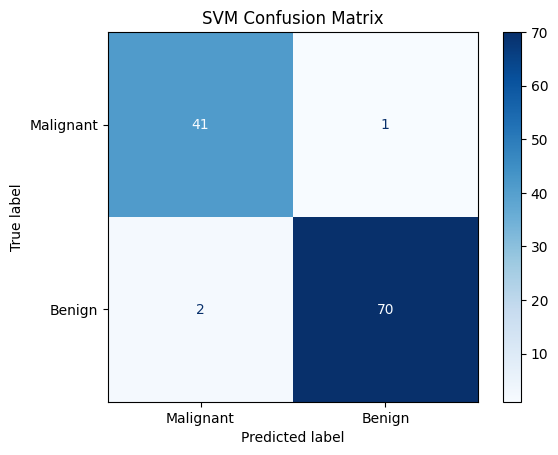

In [ ]:
import matplotlib.pyplot as plt # Import Matplotlib to display the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay  # Import ConfusionMatrixDisplay to create a visual confusion matrix
# Create and display the confusion matrix using actual and predicted labels
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Malignant', 'Benign'],
    cmap='Blues'
)

plt.title('SVM Confusion Matrix') # Add a title to the confusion matrix graph
plt.show()# Display the graph


In [ ]:
import pandas as pd # Import Pandas to create and manipulate a tabular DataFrame
# Create a DataFrame containing actual and predicted class labels
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print(results.head(10)) # Display the first 10 rows to compare actual and predicted results


     Actual  Predicted
256       0          0
428       1          1
501       0          0
363       1          0
564       0          0
464       1          1
358       1          1
343       0          0
516       0          0
567       0          0


In [ ]:
from sklearn.svm import SVC # Import SVC to create Support Vector Machine classification models
from sklearn.metrics import accuracy_score # Import accuracy_score to measure the model's prediction accuracy
kernels = ['linear', 'poly', 'rbf'] # Define the three SVM kernels to compare
# Loop through each kernel in the list
for kernel in kernels:
    model = SVC(kernel=kernel, C=1)     # Create an SVM model using the current kernel and C = 1
    model.fit(X_train, y_train)     # Train the model using the training features and labels
    predictions = model.predict(X_test)    # Predict the class labels for the testing dataset
    print(kernel, "Accuracy:", accuracy_score(y_test, predictions))     # Calculate and display the accuracy for the current kernel


linear Accuracy: 0.9736842105263158
poly Accuracy: 0.9122807017543859
rbf Accuracy: 0.9824561403508771


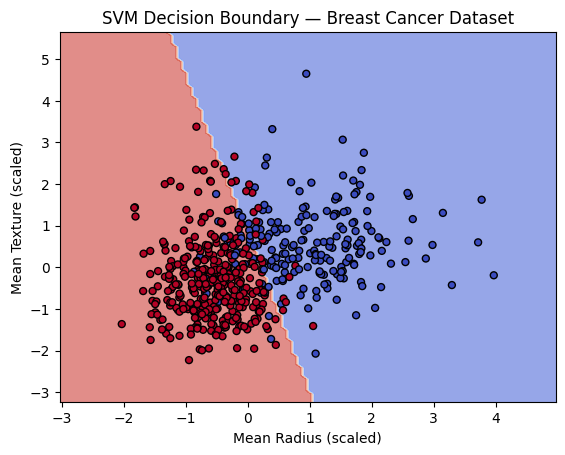

In [ ]:
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

# Load the dataset
cancer = load_breast_cancer()

# Select two features
X = cancer.data[:, :2]
y = cancer.target

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train SVM
svm = SVC(kernel='linear', C=1)
svm.fit(X_scaled, y)

# Display decision boundary
DecisionBoundaryDisplay.from_estimator(
    svm,
    X_scaled,
    response_method='predict',
    cmap=plt.cm.coolwarm,
    alpha=0.6
)

# Plot data points
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap=plt.cm.coolwarm,
    s=25,
    edgecolors='k'
)

plt.xlabel('Mean Radius (scaled)')
plt.ylabel('Mean Texture (scaled)')
plt.title('SVM Decision Boundary — Breast Cancer Dataset')
plt.show()

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Create Linear SVM model
linear_svm = SVC(kernel='linear', C=1)

# Train model
linear_svm.fit(X_train, y_train)

# Predict test data
y_pred_linear = linear_svm.predict(X_test)

# Evaluate model
print("Linear SVM Accuracy:",
      accuracy_score(y_test, y_pred_linear))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    target_names=cancer.target_names
))

Linear SVM Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [ ]:
# Create Non-Linear SVM model
nonlinear_svm = SVC(kernel='rbf', C=1, gamma='scale')

# Train model
nonlinear_svm.fit(X_train, y_train)

# Predict test data
y_pred_nonlinear = nonlinear_svm.predict(X_test)

# Evaluate model
print("Non-Linear SVM Accuracy:",
      accuracy_score(y_test, y_pred_nonlinear))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nonlinear,
    target_names=cancer.target_names
))

Non-Linear SVM Accuracy: 0.9824561403508771

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score

comparison = pd.DataFrame({
    'Model': ['Linear SVM', 'Non-Linear SVM (RBF)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_linear),
        accuracy_score(y_test, y_pred_nonlinear)
    ]
})

print(comparison)

                  Model  Accuracy
0            Linear SVM  0.973684
1  Non-Linear SVM (RBF)  0.982456


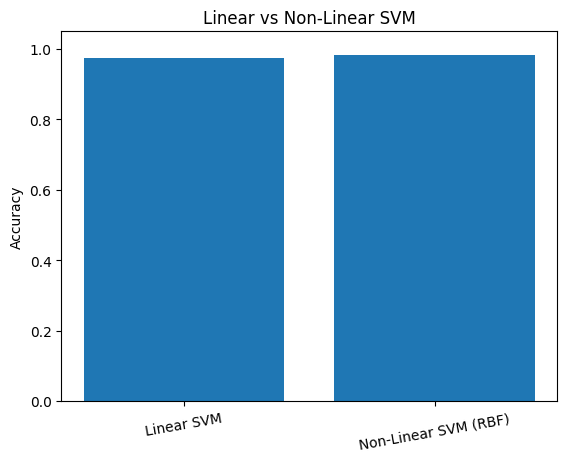

In [ ]:
import matplotlib.pyplot as plt

plt.bar(comparison['Model'], comparison['Accuracy'])
plt.ylabel('Accuracy')
plt.title('Linear vs Non-Linear SVM')
plt.ylim(0, 1.05)
plt.xticks(rotation=10)
plt.show()

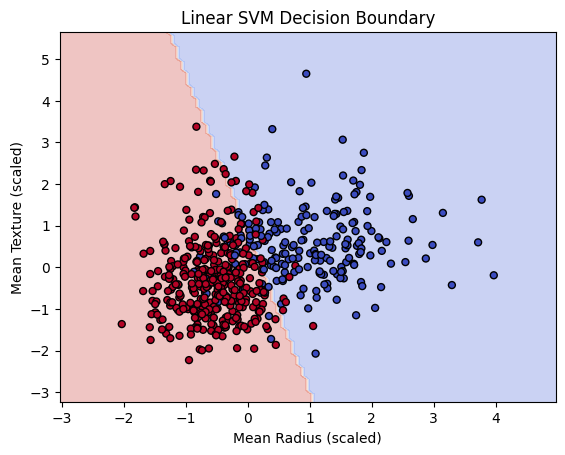

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

# Load dataset
cancer = load_breast_cancer()
X = cancer.data[:, :2]
y = cancer.target

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train Linear SVM
linear_svm = SVC(kernel='linear', C=1)
linear_svm.fit(X_scaled, y)

# Plot decision boundary
DecisionBoundaryDisplay.from_estimator(
    linear_svm,
    X_scaled,
    response_method='predict',
    cmap=plt.cm.coolwarm,
    alpha=0.3
)

# Plot data points
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=25
)

plt.xlabel('Mean Radius (scaled)')
plt.ylabel('Mean Texture (scaled)')
plt.title('Linear SVM Decision Boundary')
plt.show()

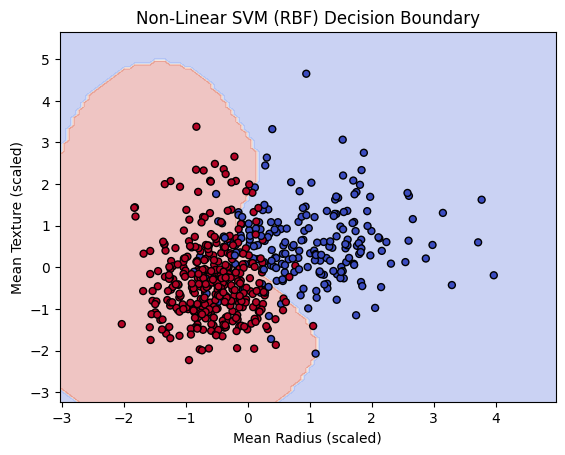

In [ ]:
# Train Non-Linear SVM using RBF kernel
rbf_svm = SVC(kernel='rbf', C=1, gamma='scale')
rbf_svm.fit(X_scaled, y)

# Plot decision boundary
DecisionBoundaryDisplay.from_estimator(
    rbf_svm,
    X_scaled,
    response_method='predict',
    cmap=plt.cm.coolwarm,
    alpha=0.3
)

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=25
)

plt.xlabel('Mean Radius (scaled)')
plt.ylabel('Mean Texture (scaled)')
plt.title('Non-Linear SVM (RBF) Decision Boundary')
plt.show()

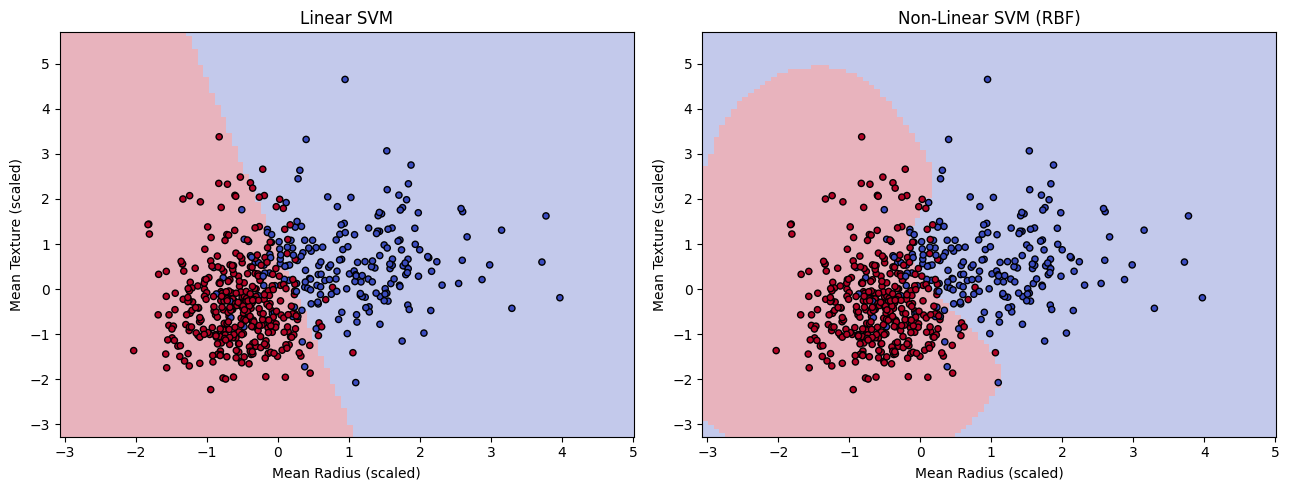

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

# Select two features for visualization
X_2d = cancer.data[:, :2]
y_2d = cancer.target

# Scale the two features
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ('Linear SVM', SVC(kernel='linear', C=1)),
    ('Non-Linear SVM (RBF)', SVC(kernel='rbf', C=1, gamma='scale'))
]

for ax, (name, model) in zip(axes, models):
    model.fit(X_2d_scaled, y_2d)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d_scaled,
        response_method='predict',
        plot_method='pcolormesh',
        cmap=plt.cm.coolwarm,
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X_2d_scaled[:, 0],
        X_2d_scaled[:, 1],
        c=y_2d,
        cmap=plt.cm.coolwarm,
        edgecolors='k',
        s=20
    )

    ax.set_title(name)
    ax.set_xlabel('Mean Radius (scaled)')
    ax.set_ylabel('Mean Texture (scaled)')

plt.tight_layout()
plt.show()

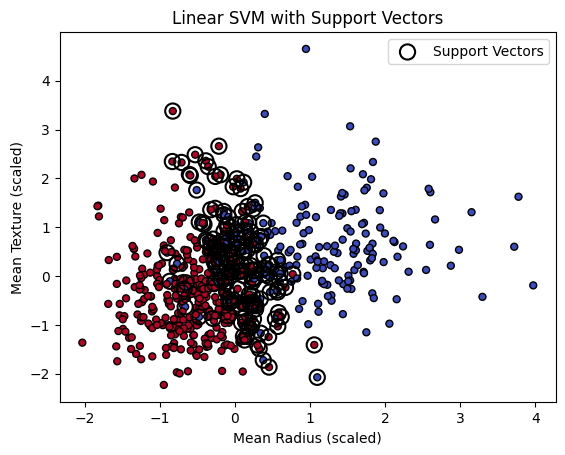

Number of support vectors per class: [78 79]


In [ ]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap=plt.cm.coolwarm,
    edgecolors='k',
    s=25
)

plt.scatter(
    linear_svm.support_vectors_[:, 0],
    linear_svm.support_vectors_[:, 1],
    s=120,
    facecolors='none',
    edgecolors='black',
    linewidths=1.5,
    label='Support Vectors'
)

plt.xlabel('Mean Radius (scaled)')
plt.ylabel('Mean Texture (scaled)')
plt.title('Linear SVM with Support Vectors')
plt.legend()
plt.show()

print("Number of support vectors per class:",
      linear_svm.n_support_)

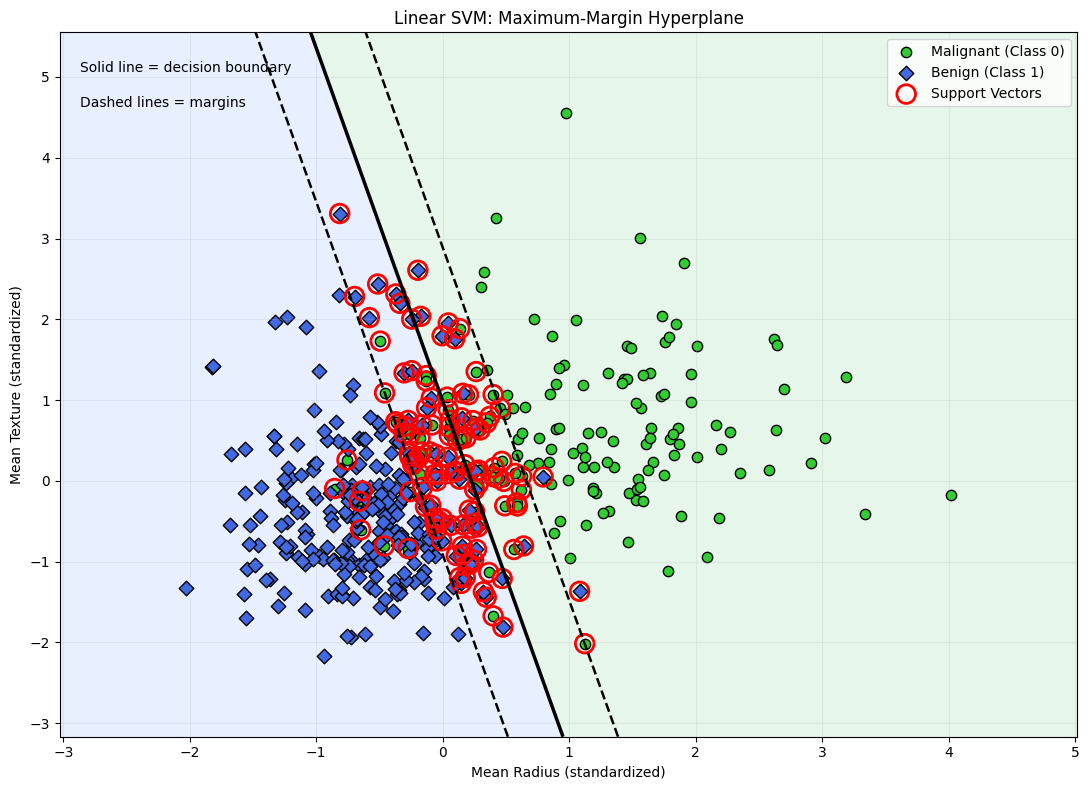

Support vectors: 127
Support vectors per class: [64 63]
Test accuracy: 0.868421052631579


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load your breast cancer dataset
cancer = load_breast_cancer()
X = cancer.data[:, :2]  # First two features only
y = cancer.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear SVM on two features
linear_svm = SVC(kernel="linear", C=1)
linear_svm.fit(X_train_scaled, y_train)

# Create a grid for plotting
X_plot = X_train_scaled
y_plot = np.asarray(y_train)

x_min = X_plot[:, 0].min() - 1
x_max = X_plot[:, 0].max() + 1
y_min = X_plot[:, 1].min() - 1
y_max = X_plot[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Calculate decision scores
Z = linear_svm.decision_function(grid).reshape(xx.shape)

# Plot classification regions
plt.figure(figsize=(11, 8))
plt.contourf(
    xx, yy, Z,
    levels=[-100, 0, 100],
    colors=["#d9f2df", "#dce8ff"],
    alpha=0.65
)

# Plot margins and decision boundary
plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["--", "-", "--"],
    linewidths=[1.8, 2.5, 1.8]
)

# Plot training samples
plt.scatter(
    X_plot[y_plot == 0, 0],
    X_plot[y_plot == 0, 1],
    c="limegreen",
    marker="o",
    s=55,
    edgecolors="black",
    label="Malignant (Class 0)"
)

plt.scatter(
    X_plot[y_plot == 1, 0],
    X_plot[y_plot == 1, 1],
    c="royalblue",
    marker="D",
    s=55,
    edgecolors="black",
    label="Benign (Class 1)"
)

# Highlight support vectors
sv = linear_svm.support_vectors_

plt.scatter(
    sv[:, 0], sv[:, 1],
    s=180,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("Mean Radius (standardized)")
plt.ylabel("Mean Texture (standardized)")
plt.title("Linear SVM: Maximum-Margin Hyperplane")

plt.text(
    0.02, 0.96,
    "Solid line = decision boundary",
    transform=plt.gca().transAxes,
    va="top"
)
plt.text(
    0.02, 0.91,
    "Dashed lines = margins",
    transform=plt.gca().transAxes,
    va="top"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Support vectors:", len(linear_svm.support_vectors_))
print("Support vectors per class:", linear_svm.n_support_)
print("Test accuracy:", linear_svm.score(X_test_scaled, y_test))
